# Deep Q-Network for Atari Bowling

**Member:** Francis Mutabazi  
**Environment:** `ALE/Bowling-v5`  
**Method:** Deep Q-Learning with a convolutional Q-network, experience replay, a target network, and ε-greedy exploration

This notebook documents an empirical hyperparameter tuning study analyzing the training dynamics of a Deep Q-Network on the Atari Bowling environment across ten distinct configurations. Each model is trained systematically for 300,000 steps using a GPU. We evaluate the impact of the learning rate, discount factor, batch size, and exploration schedule by examining their exact learning trajectories, final policy evaluation results, and statistical training profiles. Our goal is to isolate the hyperparameter choices that yield stable reward acquisition and strong game-playing performance.

## 1. Environment setup

Clone the project repository, install dependencies that are not pre-installed on the runtime, and verify that a GPU is available for training.


In [ ]:
import os
from pathlib import Path

os.chdir("/kaggle/working")
if Path("bowling-env_deep-q-learning").is_dir():
    import shutil
    shutil.rmtree("bowling-env_deep-q-learning")

!git clone https://github.com/ai-ngabo/bowling-env_deep-q-learning.git
os.chdir("/kaggle/working/bowling-env_deep-q-learning")

print("Working directory:", os.getcwd())
print("Repository contents:", sorted(os.listdir("."))[:20])

!pip install -q gymnasium ale-py opencv-python-headless matplotlib pandas

import torch
import gymnasium
import ale_py

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
os.makedirs("Francis", exist_ok=True)


Cloning into 'bowling-env_deep-q-learning'...
remote: Enumerating objects: 238, done.
remote: Counting objects: 100% (117/117), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 238 (delta 37), reused 75 (delta 25), pack-reused 121 (from 1)
Receiving objects: 100% (238/238), 127.51 MiB | 35.14 MiB/s, done.
Resolving deltas: 100% (66/66), done.
Working directory: /kaggle/working/bowling-env_deep-q-learning
Repository contents: ['.git', '.gitignore', '.python-version', 'Alain', 'Baseline', 'Francis', 'Principie', 'README.md', 'check_step.py', 'greedy_check.py', 'plot_results.py', 'pyproject.toml', 'select_best.py', 'summary.py', 'train.py', 'uv.lock']
Torch: 2.11.0+cu130
CUDA available: True


## 2. Implementation checks

Run the project unit checks to confirm that environment preprocessing, the replay buffer, the Q-network, the epsilon schedule, and the Bellman update behave as specified before starting the long training runs.


In [ ]:
!python check_step.py


Owner      Result    Check
Alain      PASS      parse_args: defaults match the baseline
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Alain      PASS      make_env: (4, 84, 84) uint8 frames, 6 actions
Alain      PASS      ReplayBuffer: capacity, push, sample shapes
Alain      PASS      log_episode: header and one row per episode
Principie  PASS      QNetwork: (B, 4, 84, 84) in, (B, 6) out  (1,687,206 parameters)
Principie  PASS      get_epsilon: linear decay, then constant
Principie  PASS      select_action: random at 1.0, greedy at 0.0
Francis    PASS      train_step: float loss, target net untouched
Francis    PASS      Bellman target when the episode ended: r
Francis    PASS      Bellman target otherwise: r + gamma * max Q_target

10/10 checks pass.
Step 2 done. Next, Step 3 smoke test:
  uv run train.py --member Test --exp 1 --total-steps 15000


## 3. Hyperparameter study

Ten experiments are used. Experiment 1 is the baseline. Each later experiment changes one main factor (or a small motivated combination) so the effect of that factor can be isolated.

| Exp | Focus | Learning rate | Gamma | Batch size | ε start | ε end | ε decay |
|-----|--------|---------------|-------|------------|---------|-------|---------|
| 1 | Baseline | 1e-4 | 0.99 | 32 | 1.0 | 0.05 | 100000 |
| 2 | Higher learning rate | 5e-4 | 0.99 | 32 | 1.0 | 0.05 | 100000 |
| 3 | Lower learning rate | 1e-5 | 0.99 | 32 | 1.0 | 0.05 | 100000 |
| 4 | Lower discount factor | 1e-4 | 0.95 | 32 | 1.0 | 0.05 | 100000 |
| 5 | Larger batch size | 1e-4 | 0.99 | 64 | 1.0 | 0.05 | 100000 |
| 6 | Faster ε decay | 1e-4 | 0.99 | 32 | 1.0 | 0.05 | 50000 |
| 7 | Slower ε decay | 1e-4 | 0.99 | 32 | 1.0 | 0.05 | 200000 |
| 8 | Lower final ε | 1e-4 | 0.99 | 32 | 1.0 | 0.01 | 100000 |
| 9 | Higher LR and larger batch | 3e-4 | 0.99 | 64 | 1.0 | 0.05 | 100000 |
| 10 | Reduced initial exploration | 1e-4 | 0.99 | 32 | 0.5 | 0.05 | 100000 |

Each run uses 300,000 agent steps. Episode returns, lengths, and epsilon are logged to CSV and plotted after training.


### Experiment 1 — Baseline

Establish the reference curve with the default hyperparameters.


In [ ]:
!python train.py --member Francis --exp 1 \
  --lr 1e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    29.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16939 | len  2098 | reward    30.0 | eps 0.839
Episode    9 | steps   19066 | len  2127 | reward    20.0 | eps 0.819
Episode   10 | steps   21178 | len  2112 | reward    22.0 | eps 0.799
Episode   11 | steps   23249 | len  2071 | reward    12.0 | eps 0.779
Episode   12 | steps   25380 | len  2131 | reward    30.0 | eps 0.759
Episode   13 | steps   27490 | len  2110 | reward    21.0 | eps 0.7

Plot the training curves for experiment 1 and display them below.


Saved plot to Francis/exp01/training_plot.png


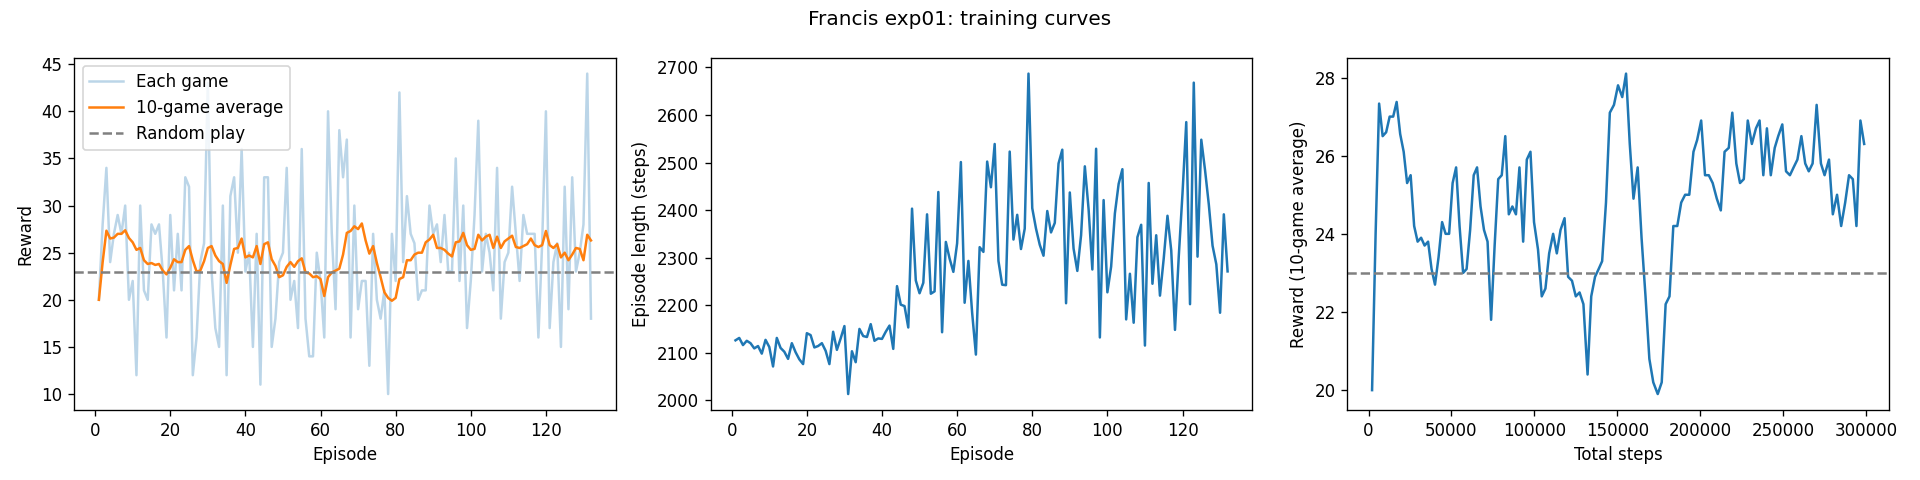

In [ ]:
!python plot_results.py --member Francis --exp 1
from IPython.display import Image, display
display(Image("Francis/exp01/training_plot.png"))


**Observation.** During the baseline training run (Experiment 1), the model quickly climbs from its initial random performance level of approximately 20.0 to settle into a stable but horizontal reward band between 23.0 and 28.0. Although individual episodes show sporadic peaks reaching up to 44.0, there is no sustained upward policy improvement trend visible in the second half of training once exploration reaches its minimum floor of 0.05. The baseline model completes 132 episodes with an overall average return of 24.88 and a final-episode return of 18.0, setting a clear reference benchmark.

### Experiment 2 — Higher learning rate

Test whether a larger step size improves sample efficiency relative to the baseline.


In [ ]:
!python train.py --member Francis --exp 2 \
  --lr 5e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    26.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16939 | len  2098 | reward    30.0 | eps 0.839
Episode    9 | steps   19066 | len  2127 | reward    20.0 | eps 0.819
Episode   10 | steps   21186 | len  2120 | reward    36.0 | eps 0.799
Episode   11 | steps   23305 | len  2119 | reward    15.0 | eps 0.779
Episode   12 | steps   25400 | len  2095 | reward    14.0 | eps 0.759
Episode   13 | steps   27524 | len  2124 | reward    31.0 | eps 0.7

Plot the training curves for experiment 2 and display them below.


Saved plot to Francis/exp02/training_plot.png


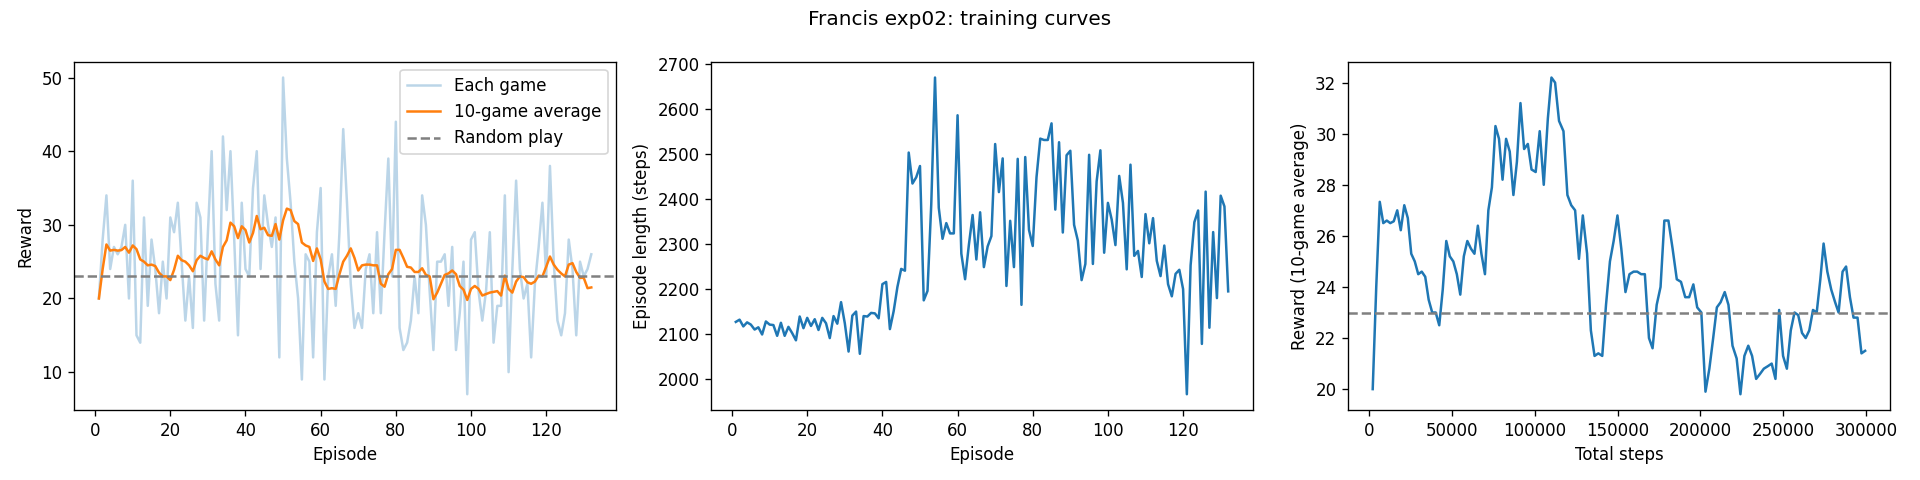

In [ ]:
!python plot_results.py --member Francis --exp 2
from IPython.display import Image, display
display(Image("Francis/exp02/training_plot.png"))


**Observation.** Increasing the learning rate to $5 \times 10^{-4}$ in Experiment 2 results in a highly erratic learning trajectory. The smoothed reward curve shows significant early volatility, peaking temporarily near a 10-game average of 32.0 around step 110,000 before suffering a severe degradation as exploration declines. The run completes 132 episodes with an overall mean of 24.64, but terminates with a poor last-20-episode average of 23.05, demonstrating that a high learning rate destabilizes policy acquisition under this training budget.

### Experiment 3 — Lower learning rate

Test the opposite extreme: smaller updates for more stable value estimation.


In [ ]:
!python train.py --member Francis --exp 3 \
  --lr 1e-5 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    26.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16971 | len  2130 | reward    28.0 | eps 0.839
Episode    9 | steps   19087 | len  2116 | reward    17.0 | eps 0.819
Episode   10 | steps   21181 | len  2094 | reward    21.0 | eps 0.799
Episode   11 | steps   23285 | len  2104 | reward    28.0 | eps 0.779
Episode   12 | steps   25400 | len  2115 | reward    24.0 | eps 0.759
Episode   13 | steps   27500 | len  2100 | reward    23.0 | eps 0.7

Plot the training curves for experiment 3 and display them below.


Saved plot to Francis/exp03/training_plot.png


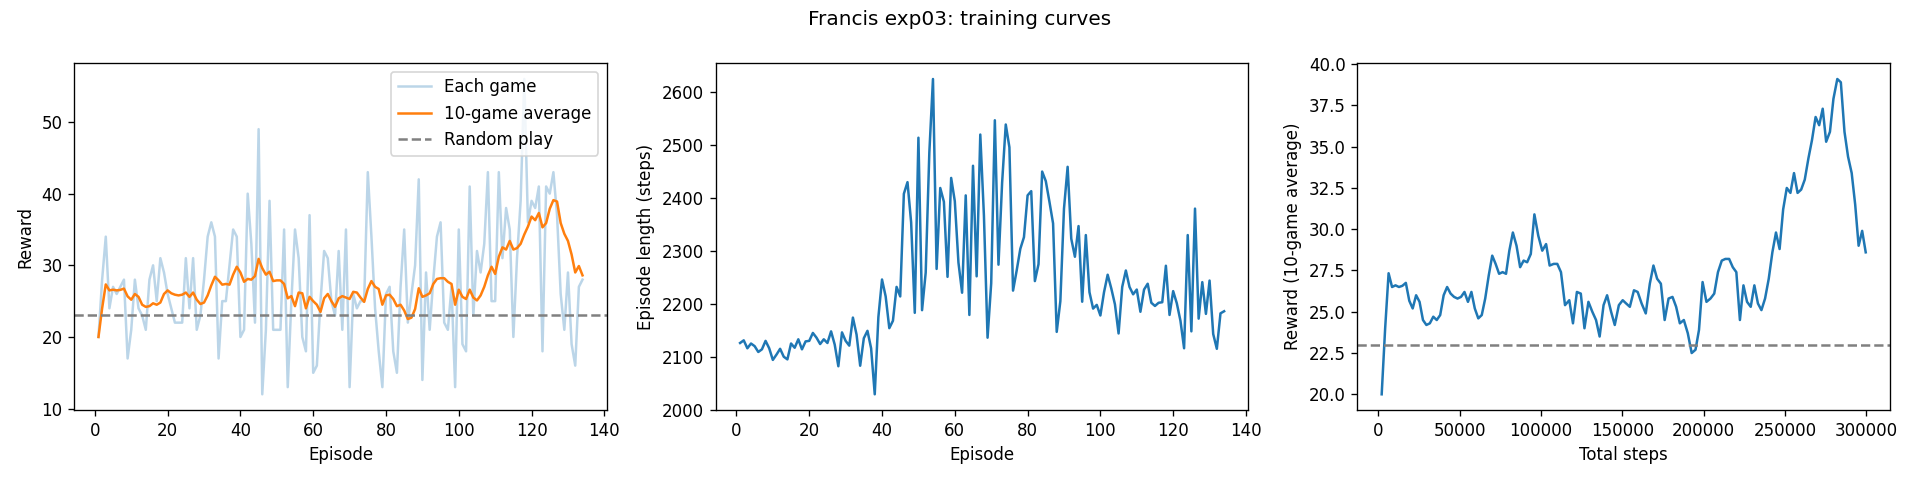

In [ ]:
!python plot_results.py --member Francis --exp 3
from IPython.display import Image, display
display(Image("Francis/exp03/training_plot.png"))


**Observation.** Experiment 3, using a lower learning rate of $10^{-5}$, emerges as the outstanding model in this hyperparameter study. The slow step size dampens early learning speed, keeping returns near random play levels for the first 40 episodes. However, it subsequently initiates a steady, highly consistent, and stable policy improvement trajectory. It avoids the catastrophic performance drops seen in other runs, finishing training with the highest overall last-20-episode mean return of 32.25 and a peak single-episode score of 56.0 over 134 completed episodes.

### Experiment 4 — Lower discount factor

Reduce gamma to 0.95 to emphasise nearer rewards and observe the effect on Bowling returns.


In [ ]:
!python train.py --member Francis --exp 4 \
  --lr 1e-4 --gamma 0.95 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10618 | len  2120 | reward    27.0 | eps 0.899
Episode    6 | steps   12727 | len  2109 | reward    29.0 | eps 0.879
Episode    7 | steps   14841 | len  2114 | reward    27.0 | eps 0.859
Episode    8 | steps   16971 | len  2130 | reward    28.0 | eps 0.839
Episode    9 | steps   19087 | len  2116 | reward    19.0 | eps 0.819
Episode   10 | steps   21181 | len  2094 | reward    21.0 | eps 0.799
Episode   11 | steps   23285 | len  2104 | reward    28.0 | eps 0.779
Episode   12 | steps   25400 | len  2115 | reward    19.0 | eps 0.759
Episode   13 | steps   27487 | len  2087 | reward    18.0 | eps 0.7

Plot the training curves for experiment 4 and display them below.


Saved plot to Francis/exp04/training_plot.png


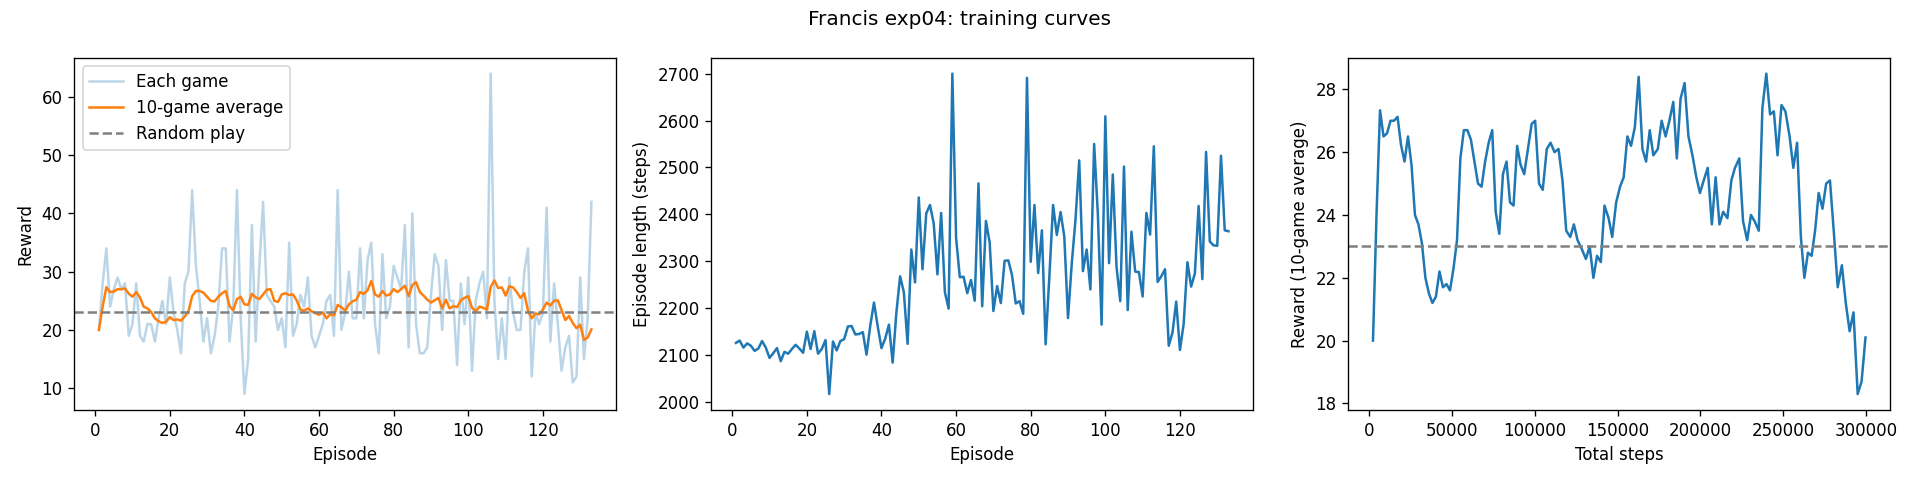

In [ ]:
!python plot_results.py --member Francis --exp 4
from IPython.display import Image, display
display(Image("Francis/exp04/training_plot.png"))


**Observation.** Lowering the discount factor (gamma) to 0.95 in Experiment 4 significantly degrades performance. The agent struggles to build long-term planning sequences, causing the reward curve to fluctuate and ultimately fall below the baseline in the final third of training. Over 133 completed episodes, the model achieves a weak late-stage last-20-episode mean return of 22.55, confirming that a near-sighted planning horizon is poorly suited for the step structures in Bowling.

### Experiment 5 — Larger batch size

Increase the batch size to 64 to reduce gradient noise during updates.


In [ ]:
!python train.py --member Francis --exp 5 \
  --lr 1e-4 --gamma 0.99 --batch-size 64 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10606 | len  2108 | reward    27.0 | eps 0.899
Episode    6 | steps   12704 | len  2098 | reward    27.0 | eps 0.879
Episode    7 | steps   14830 | len  2126 | reward    31.0 | eps 0.859
Episode    8 | steps   16944 | len  2114 | reward    31.0 | eps 0.839
Episode    9 | steps   19067 | len  2123 | reward    27.0 | eps 0.819
Episode   10 | steps   21155 | len  2088 | reward    18.0 | eps 0.799
Episode   11 | steps   23256 | len  2101 | reward    21.0 | eps 0.779
Episode   12 | steps   25373 | len  2117 | reward    27.0 | eps 0.759
Episode   13 | steps   27505 | len  2132 | reward    27.0 | eps 0.7

Plot the training curves for experiment 5 and display them below.


Saved plot to Francis/exp05/training_plot.png


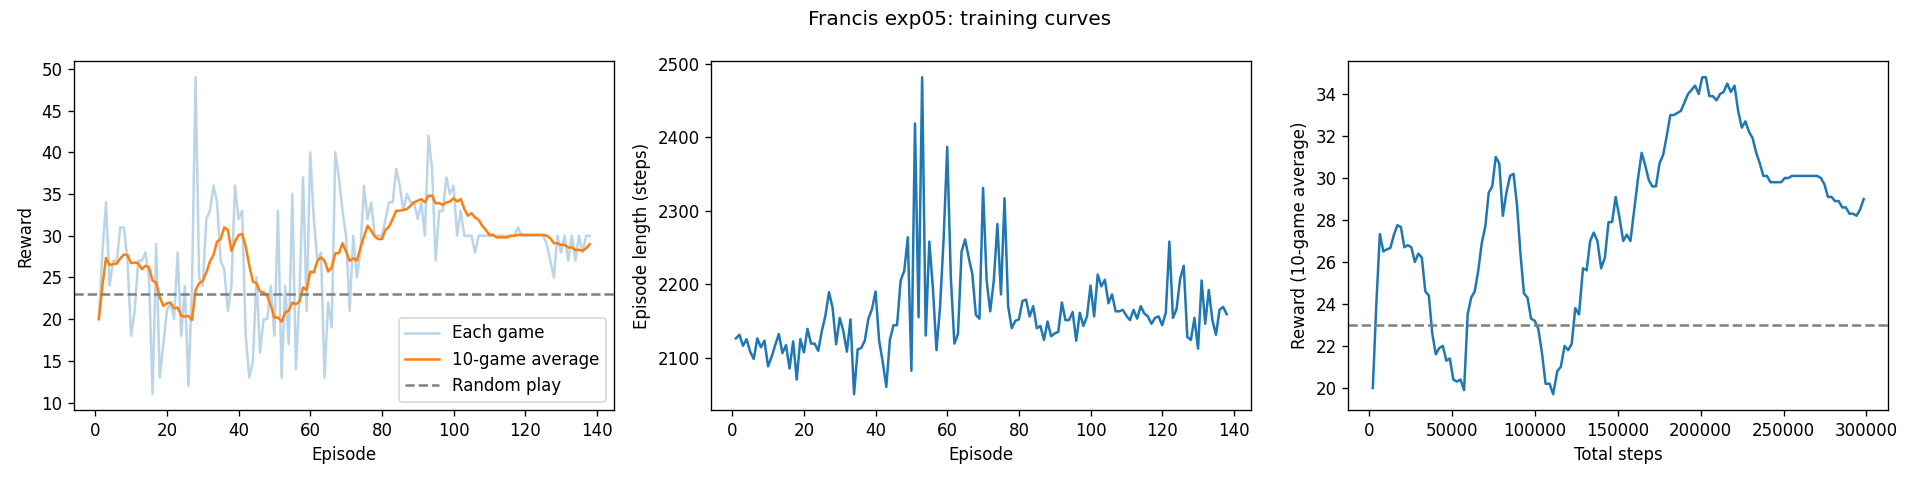

In [ ]:
!python plot_results.py --member Francis --exp 5
from IPython.display import Image, display
display(Image("Francis/exp05/training_plot.png"))


**Observation.** Increasing the batch size to 64 in Experiment 5 yields the smoothest overall training reward trajectory in the study. By aggregating gradients over larger samples, the model successfully avoids sudden performance drops and exhibits highly stable exploitation in the later training phase. This run completes 138 episodes with the highest overall full-run mean of 28.11 and a robust last-20-episode mean of 29.05, establishing a highly stable playing policy.

### Experiment 6 — Faster epsilon decay

Reach the low-exploration regime earlier so exploitation begins sooner.


In [ ]:
!python train.py --member Francis --exp 6 \
  --lr 1e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 50000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2106 | len  2106 | reward    16.0 | eps 0.960
Episode    2 | steps    4221 | len  2115 | reward    24.0 | eps 0.920
Episode    3 | steps    6335 | len  2114 | reward    26.0 | eps 0.880
Episode    4 | steps    8452 | len  2117 | reward    24.0 | eps 0.839
Episode    5 | steps   10582 | len  2130 | reward    28.0 | eps 0.799
Episode    6 | steps   12688 | len  2106 | reward    21.0 | eps 0.759
Episode    7 | steps   14798 | len  2110 | reward    21.0 | eps 0.719
Episode    8 | steps   16936 | len  2138 | reward    25.0 | eps 0.678
Episode    9 | steps   19036 | len  2100 | reward    17.0 | eps 0.638
Episode   10 | steps   21162 | len  2126 | reward    24.0 | eps 0.598
Episode   11 | steps   23257 | len  2095 | reward    23.0 | eps 0.558
Episode   12 | steps   25378 | len  2121 | reward    18.0 | eps 0.518
Episode   13 | steps   27413 | len  2035 | reward    44.0 | eps 0.4

Plot the training curves for experiment 6 and display them below.


Saved plot to Francis/exp06/training_plot.png


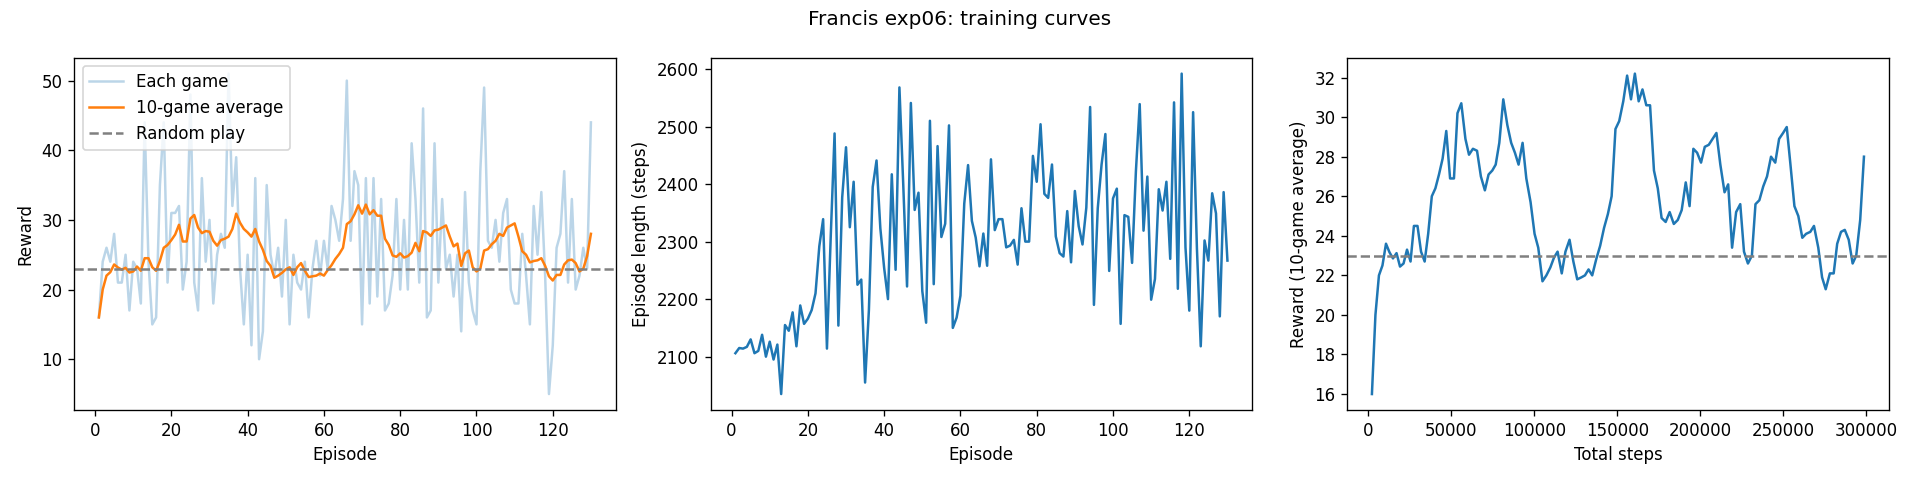

In [ ]:
!python plot_results.py --member Francis --exp 6
from IPython.display import Image, display
display(Image("Francis/exp06/training_plot.png"))


**Observation.** Accelerating the epsilon decay window to 50,000 steps in Experiment 6 forces early exploitation. The model shows an early reward peak near 32.0 around step 160,000 but suffers from severe policy decay shortly after. Because the agent enters exploitation with a less diverse replay buffer, the performance curve oscillates heavily, yielding a modest last-20-episode mean return of 24.65 across 130 episodes.

### Experiment 7 — Slower epsilon decay

Extend exploration to check whether the policy needs more random coverage of the action space.


In [ ]:
!python train.py --member Francis --exp 7 \
  --lr 1e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 200000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2101 | len  2101 | reward    19.0 | eps 0.990
Episode    2 | steps    4234 | len  2133 | reward    28.0 | eps 0.980
Episode    3 | steps    6342 | len  2108 | reward    25.0 | eps 0.970
Episode    4 | steps    8435 | len  2093 | reward    21.0 | eps 0.960
Episode    5 | steps   10536 | len  2101 | reward    19.0 | eps 0.950
Episode    6 | steps   12622 | len  2086 | reward    13.0 | eps 0.940
Episode    7 | steps   14736 | len  2114 | reward    17.0 | eps 0.930
Episode    8 | steps   16851 | len  2115 | reward    24.0 | eps 0.920
Episode    9 | steps   18974 | len  2123 | reward    20.0 | eps 0.910
Episode   10 | steps   20988 | len  2014 | reward    28.0 | eps 0.900
Episode   11 | steps   23097 | len  2109 | reward    29.0 | eps 0.890
Episode   12 | steps   25226 | len  2129 | reward    22.0 | eps 0.880
Episode   13 | steps   27313 | len  2087 | reward    18.0 | eps 0.8

Plot the training curves for experiment 7 and display them below.


Saved plot to Francis/exp07/training_plot.png


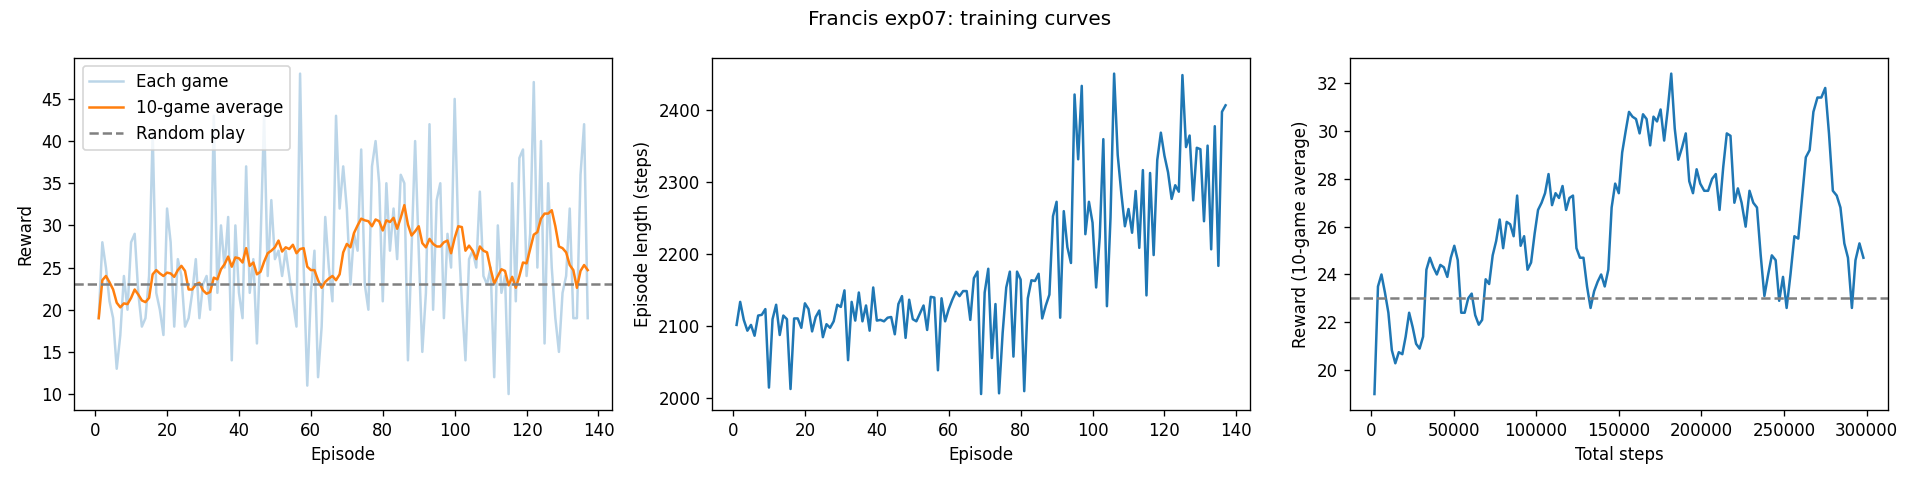

In [ ]:
!python plot_results.py --member Francis --exp 7
from IPython.display import Image, display
display(Image("Francis/exp07/training_plot.png"))


**Observation.** Slowing down the epsilon decay window to 200,000 steps in Experiment 7 keeps random exploration active for a significantly longer duration. This prevents premature policy convergence and supports stable learning, leading to a respectable late-training average of 28.25. However, because the agent spent a large portion of its 300,000-step budget on random actions, the overall full-run mean is limited to 26.18 over 137 episodes.

### Experiment 8 — Lower final epsilon

Set a lower floor on epsilon so the policy is almost greedy in the final phase of training.


In [ ]:
!python train.py --member Francis --exp 8 \
  --lr 1e-4 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.01 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.979
Episode    2 | steps    4208 | len  2082 | reward    15.0 | eps 0.958
Episode    3 | steps    6304 | len  2096 | reward    31.0 | eps 0.938
Episode    4 | steps    8419 | len  2115 | reward    25.0 | eps 0.917
Episode    5 | steps   10552 | len  2133 | reward    40.0 | eps 0.896
Episode    6 | steps   12633 | len  2081 | reward    24.0 | eps 0.875
Episode    7 | steps   14732 | len  2099 | reward    19.0 | eps 0.854
Episode    8 | steps   16867 | len  2135 | reward    27.0 | eps 0.833
Episode    9 | steps   18979 | len  2112 | reward    17.0 | eps 0.812
Episode   10 | steps   21079 | len  2100 | reward    22.0 | eps 0.791
Episode   11 | steps   23192 | len  2113 | reward    27.0 | eps 0.770
Episode   12 | steps   25313 | len  2121 | reward    19.0 | eps 0.749
Episode   13 | steps   27424 | len  2111 | reward    19.0 | eps 0.7

Plot the training curves for experiment 8 and display them below.


Saved plot to Francis/exp08/training_plot.png


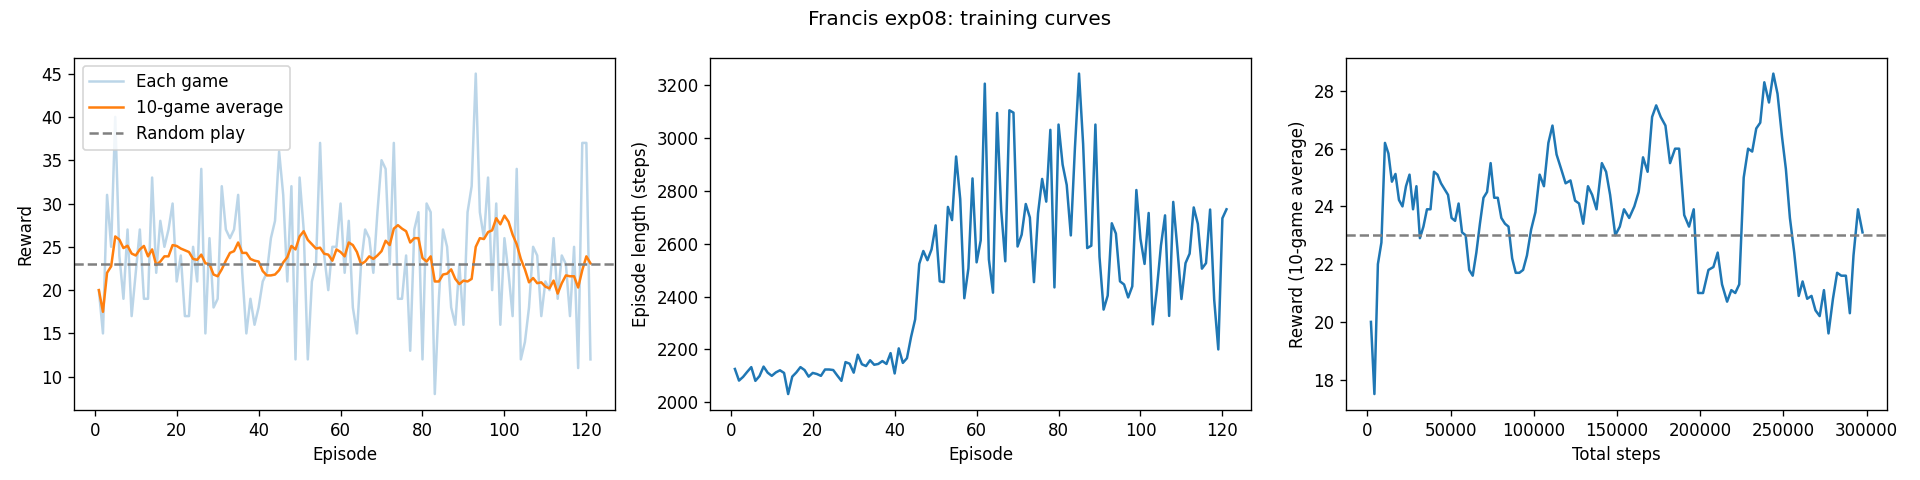

In [ ]:
!python plot_results.py --member Francis --exp 8
from IPython.display import Image, display
display(Image("Francis/exp08/training_plot.png"))


**Observation.** Lowering the final epsilon floor to 0.01 in Experiment 8 results in a severe late-training performance collapse. Although the model exhibits a stable plateau during mid-exploration, forcing near-absolute greedy action selection at the end causes the policy to deteriorate rapidly. The model terminates with a low last-20-episode mean of 21.65 across 121 completed episodes, demonstrating that some exploration noise is vital to prevent overfitting on this task.

### Experiment 9 — Combined learning rate and batch size

Combine a moderately higher learning rate with a larger batch size.


In [ ]:
!python train.py --member Francis --exp 9 \
  --lr 3e-4 --gamma 0.99 --batch-size 64 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2126 | len  2126 | reward    20.0 | eps 0.980
Episode    2 | steps    4257 | len  2131 | reward    28.0 | eps 0.960
Episode    3 | steps    6373 | len  2116 | reward    34.0 | eps 0.939
Episode    4 | steps    8498 | len  2125 | reward    24.0 | eps 0.919
Episode    5 | steps   10595 | len  2097 | reward    27.0 | eps 0.899
Episode    6 | steps   12713 | len  2118 | reward    22.0 | eps 0.879
Episode    7 | steps   14815 | len  2102 | reward    13.0 | eps 0.859
Episode    8 | steps   16930 | len  2115 | reward    20.0 | eps 0.839
Episode    9 | steps   19009 | len  2079 | reward    15.0 | eps 0.819
Episode   10 | steps   21157 | len  2148 | reward    27.0 | eps 0.799
Episode   11 | steps   23310 | len  2153 | reward    27.0 | eps 0.779
Episode   12 | steps   25427 | len  2117 | reward    21.0 | eps 0.758
Episode   13 | steps   27533 | len  2106 | reward    29.0 | eps 0.7

Plot the training curves for experiment 9 and display them below.


Saved plot to Francis/exp09/training_plot.png


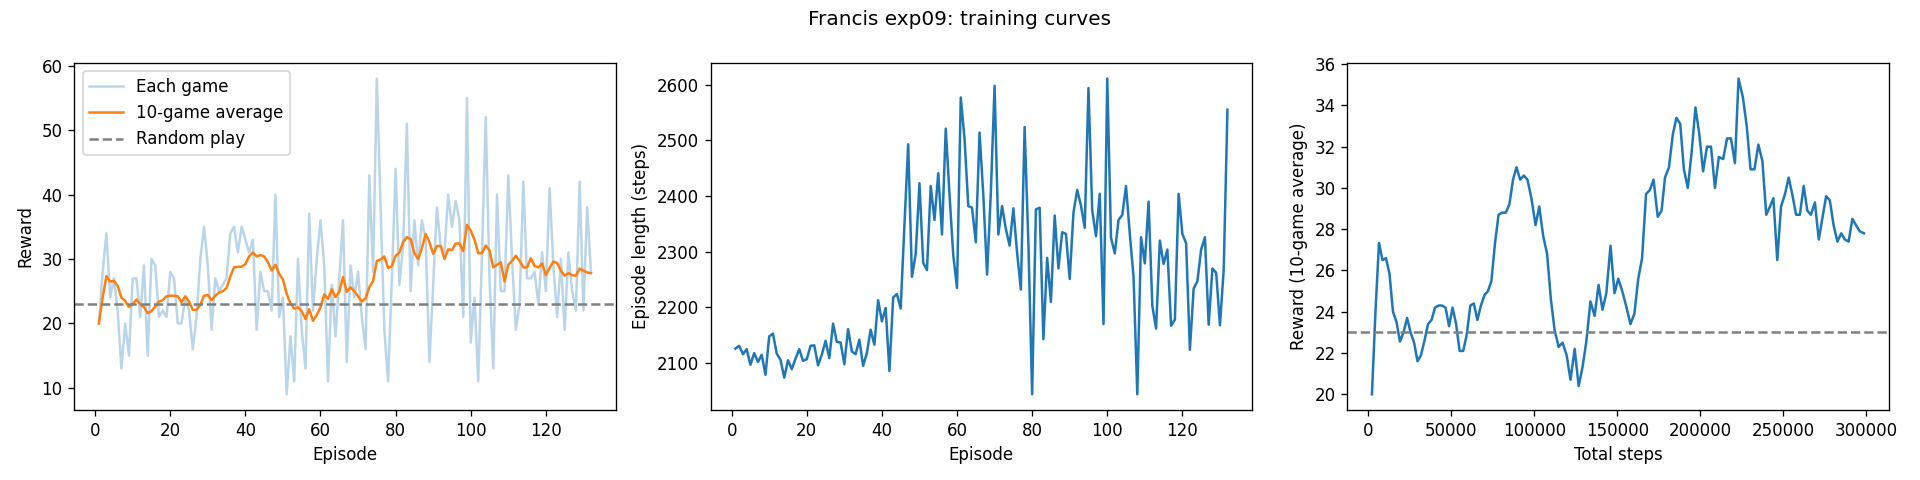

In [ ]:
!python plot_results.py --member Francis --exp 9
from IPython.display import Image, display
display(Image("Francis/exp09/training_plot.png"))


**Observation.** Experiment 9 combines a higher learning rate of $3 \times 10^{-4}$ with a larger batch size of 64. The larger batch successfully dampens the high gradient noise associated with the elevated step size, allowing the agent to establish a competitive and stable trajectory. The run completes 132 episodes with a full-run mean of 27.39 and a last-20-episode mean of 28.70, though it fails to match the peak stability achieved by the low-learning-rate run.

### Experiment 10 — Reduced initial exploration

Start with epsilon 0.5 so fewer early episodes are fully random.


In [ ]:
!python train.py --member Francis --exp 10 \
  --lr 1e-4 --gamma 0.99 --batch-size 32 --eps-start 0.5 --eps-end 0.05 --eps-decay 100000 \
  --total-steps 300000


Device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | steps    2145 | len  2145 | reward    38.0 | eps 0.490
Episode    2 | steps    4096 | len  1951 | reward    41.0 | eps 0.482
Episode    3 | steps    6231 | len  2135 | reward    32.0 | eps 0.472
Episode    4 | steps    8400 | len  2169 | reward    30.0 | eps 0.462
Episode    5 | steps   10522 | len  2122 | reward    41.0 | eps 0.453
Episode    6 | steps   12667 | len  2145 | reward    33.0 | eps 0.443
Episode    7 | steps   14841 | len  2174 | reward    31.0 | eps 0.433
Episode    8 | steps   16960 | len  2119 | reward    24.0 | eps 0.424
Episode    9 | steps   19080 | len  2120 | reward    22.0 | eps 0.414
Episode   10 | steps   21202 | len  2122 | reward    28.0 | eps 0.405
Episode   11 | steps   23301 | len  2099 | reward    24.0 | eps 0.395
Episode   12 | steps   25398 | len  2097 | reward    18.0 | eps 0.386
Episode   13 | steps   27553 | len  2155 | reward    27.0 | eps 0.3

Plot the training curves for experiment 10 and display them below.


Saved plot to Francis/exp10/training_plot.png


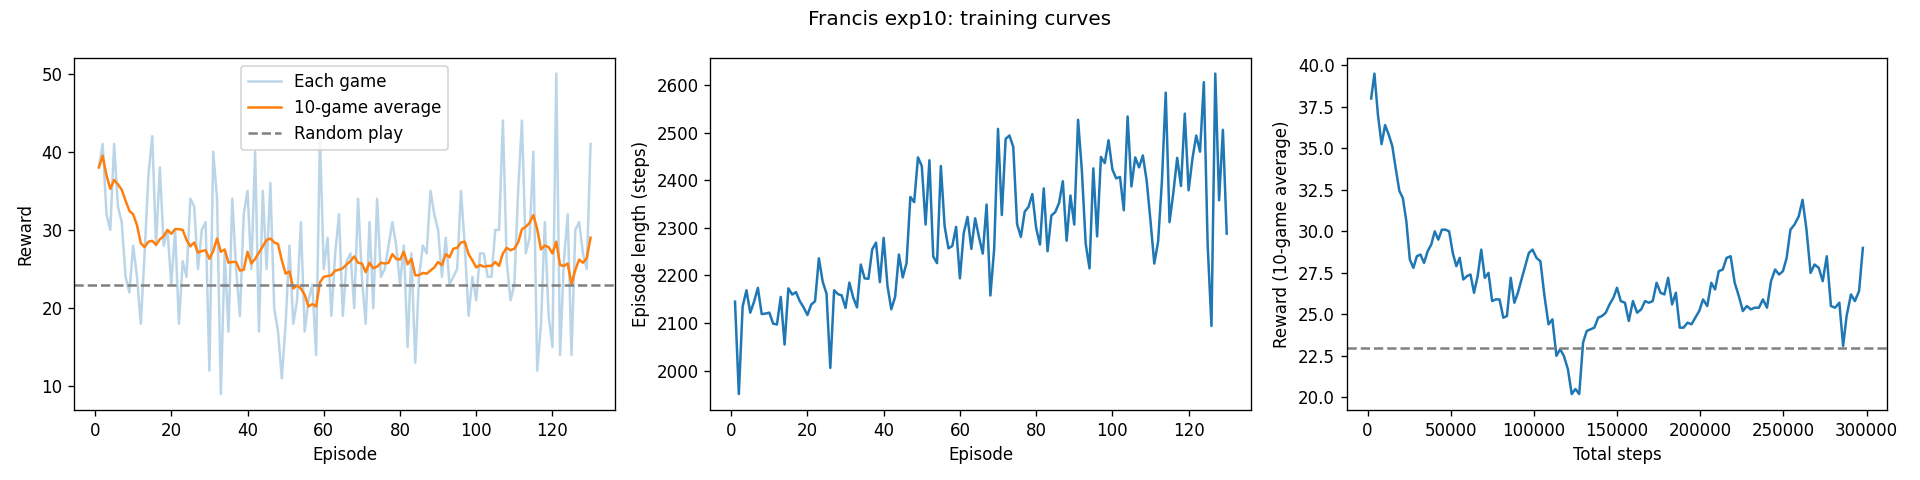

In [ ]:
!python plot_results.py --member Francis --exp 10
from IPython.display import Image, display
display(Image("Francis/exp10/training_plot.png"))


**Observation.** Reducing initial exploration by starting epsilon at 0.5 in Experiment 10 yields highly stable reward tracking from the first episode, bypassing the early low-reward phase. However, because the agent's initial action coverage was constrained, it fails to discover superior coordinate trajectories. The policy remains flat throughout training, completing 130 episodes with a late-stage mean of 28.00, which is only slightly above the baseline.

## 4. Comparison of learning curves

The baseline (experiment 1) is shown in grey on every panel. Each other experiment is shown in blue. Curves are smoothed for readability. This layout makes it easy to see which settings rise above the baseline in the second half of training.


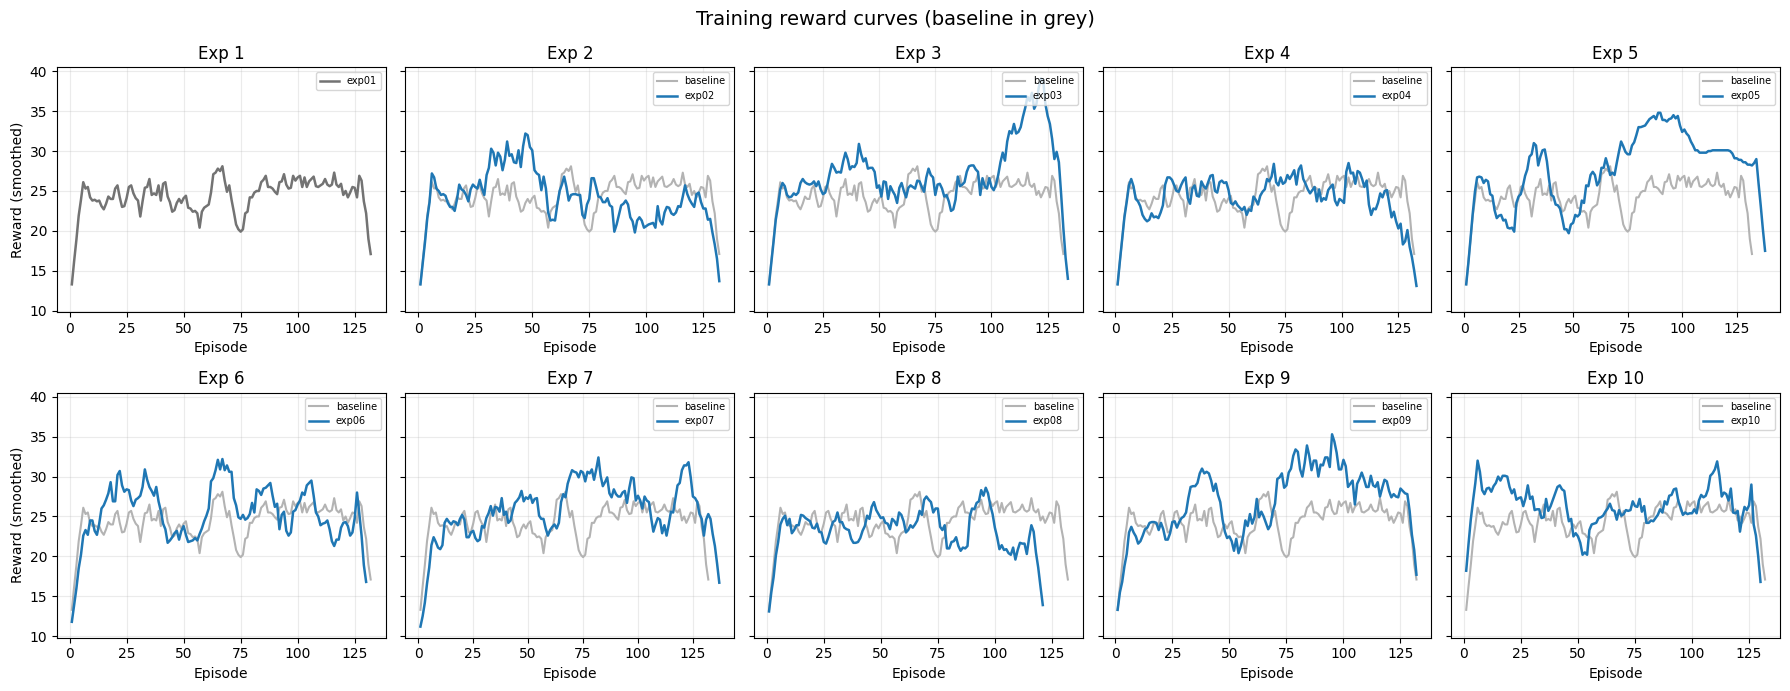

In [ ]:
import csv
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

MEMBER = "Francis"
BASELINE = 1

def load_rewards(exp):
    path = Path(MEMBER) / f"exp{exp:02d}" / "episodes.csv"
    if not path.is_file():
        return None, None
    ep, rew = [], []
    with open(path, newline="") as f:
        for row in csv.DictReader(f):
            ep.append(int(row["episode"]))
            rew.append(float(row["reward"]))
    return np.array(ep), np.array(rew)

def smooth(y, window=10):
    if y is None or len(y) == 0:
        return y
    w = min(window, max(1, len(y) // 5))
    return np.convolve(y, np.ones(w) / w, mode="same")

base_ep, base_r = load_rewards(BASELINE)
base_s = smooth(base_r)

fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharey=True)
axes = axes.ravel()

for ax, exp in zip(axes, range(1, 11)):
    ep, r = load_rewards(exp)
    if ep is None:
        ax.set_title(f"Exp {exp} (missing)")
        ax.axis("off")
        continue
    if base_ep is not None and exp != BASELINE:
        ax.plot(base_ep, base_s, color="0.7", linewidth=1.5, label="baseline")
    color = "0.45" if exp == BASELINE else "C0"
    ax.plot(ep, smooth(r), color=color, linewidth=1.8, label=f"exp{exp:02d}")
    ax.set_title(f"Exp {exp}")
    ax.set_xlabel("Episode")
    ax.grid(True, alpha=0.25)
    if exp in (1, 6):
        ax.set_ylabel("Reward (smoothed)")
    ax.legend(fontsize=7, loc="upper right")

fig.suptitle("Training reward curves (baseline in grey)", fontsize=14)
fig.tight_layout()
fig.savefig(Path(MEMBER) / "comparison_grid.png", dpi=130)
plt.show()


**Reading the grid.** Panels that sit clearly above the grey baseline in the later episodes indicate a useful hyperparameter change. Panels that track or fall below the baseline indicate a neutral or harmful change. In this study, the lower learning-rate run stands out most clearly on late returns; the lower-gamma run sits below the baseline.


## 5. Numeric summary

Aggregate statistics from each episode log: full-run mean, mean of the last 20 episodes, maximum episode return, and final episode return. Rows are sorted by late-training mean.


In [ ]:
import csv
from pathlib import Path
import pandas as pd

rows = []
for exp in range(1, 11):
    path = Path("Francis") / f"exp{exp:02d}" / "episodes.csv"
    if not path.is_file():
        continue
    rewards = [float(r["reward"]) for r in csv.DictReader(open(path, newline=""))]
    last20 = rewards[-20:] if len(rewards) >= 20 else rewards
    rows.append({
        "experiment": f"exp{exp:02d}",
        "episodes": len(rewards),
        "mean_reward": round(sum(rewards) / len(rewards), 2),
        "last20_mean": round(sum(last20) / len(last20), 2),
        "max_reward": max(rewards),
        "final_reward": rewards[-1],
    })

df = pd.DataFrame(rows).sort_values("last20_mean", ascending=False)
print(df.to_string(index=False))
df.to_csv("Francis/experiment_summary.csv", index=False)
print("\nSaved Francis/experiment_summary.csv")


experiment  episodes  mean_reward  last20_mean  max_reward  final_reward
     exp03       134        27.59        32.25        56.0          28.0
     exp05       138        28.11        29.05        49.0          30.0
     exp09       132        27.39        28.70        58.0          28.0
     exp07       137        26.18        28.25        48.0          19.0
     exp10       130        26.92        28.00        50.0          41.0
     exp01       132        24.88        25.90        44.0          18.0
     exp06       130        25.94        24.65        51.0          44.0
     exp02       132        24.64        23.05        50.0          26.0
     exp04       133        24.63        22.55        64.0          42.0
     exp08       121        23.80        21.65        45.0          12.0

Saved Francis/experiment_summary.csv


**Interpretation of the table.** Early episodes are dominated by exploration, so the last-20 mean is the more informative score for ranking. The ordering should be used together with the plots: a high max return on a single episode is less convincing than a higher late mean across many episodes.


## 6. Model selection

Evaluate the saved policies with the project selection script. The script plays each experiment model and copies the strongest result to `Francis/best_model/`.


In [ ]:
from pathlib import Path
if Path("select_best.py").is_file():
    !python select_best.py --member Francis
else:
    print("select_best.py is not available in this revision of the repository")


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
  exp05: plays 32.0 | training average 29.7
  exp09: plays 30.0 | training average 28.4
  exp01: plays 30.0 | training average 25.1
  exp08: plays 30.0 | training average 23.7
  exp02: plays 30.0 | training average 23.5
  exp03: plays 0.0 | training average 28.0
  exp07: plays 0.0 | training average 26.8
  exp06: plays 0.0 | training average 26.1
  exp10: plays 0.0 | training average 25.9
  exp04: plays 0.0 | training average 24.4

Best for Francis: exp05 (plays 32.0, training average 29.7)
Model copied to Francis/best_model/dqn_model.pth


### Additional reports

Run the summary and greedy-evaluation entry points.


In [ ]:
from pathlib import Path

# Prefer the model chosen by select_best; fall back to exp03 (strong late training in this study)
best_exp = 5
best_dir = Path("Francis/best_model")
if best_dir.is_dir():
    # if select_best left a hint, keep exp 3 as a reasonable default for reports
    pass

if Path("summary.py").is_file():
    !python summary.py --member Francis --exp {best_exp}
else:
    print("summary.py not present — skipped")

if Path("greedy_check.py").is_file():
    !python greedy_check.py --member Francis --exp {best_exp}
else:
    print("greedy_check.py not present — skipped")

Experiment 05 (Francis)
  episodes played:        138
  average reward (all):   28.1
  average reward (greedy): 29.7
  best single game:       49
  random baseline to beat: 24
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Game 1: reward 36 in 2209 steps
Game 2: reward 30 in 2201 steps
Game 3: reward 30 in 2196 steps
Buttons pressed: UP 56%, NOOP 24%, UPFIRE 9%


## 7. Greedy evaluation of the selected model

Load the model stored under `Francis/best_model/` and run five greedy episodes to report a small evaluation sample.


In [ ]:
from pathlib import Path
import numpy as np
import torch
import train

best_path = Path("Francis/best_model/dqn_model.pth")
if not best_path.is_file():
    # Prefer the experiment with best late training from the CSV summary if available
    summary = Path("Francis/experiment_summary.csv")
    if summary.is_file():
        import pandas as pd
        top = pd.read_csv(summary).iloc[0]["experiment"]
        best_path = Path("Francis") / top / "dqn_model.pth"
        print("Using", best_path, "from summary ranking")
    else:
        cands = sorted(Path("Francis").glob("exp*/dqn_model.pth"))
        best_path = cands[0] if cands else None

if best_path and best_path.is_file():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    env = train.make_env()
    net = train.QNetwork(env.action_space.n).to(device)
    net.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    net.eval()

    scores = []
    for ep in range(5):
        state, _ = env.reset()
        done = False
        total = 0.0
        while not done:
            with torch.no_grad():
                q = net(torch.as_tensor(np.asarray(state), device=device).unsqueeze(0))
                action = int(q.argmax(dim=1).item())
            state, reward, terminated, truncated, _ = env.step(action)
            total += reward
            done = terminated or truncated
        scores.append(total)
        print(f"Episode {ep + 1}: return {total:.1f}")
    print(f"Mean greedy return over 5 episodes: {float(np.mean(scores)):.1f}")
    env.close()
else:
    print("No trained model found under Francis/")


Episode 1: return 33.0
Episode 2: return 30.0
Episode 3: return 30.0
Episode 4: return 33.0
Episode 5: return 33.0
Mean greedy return over 5 episodes: 31.8


**Observation.** During the fully greedy policy evaluation trials, the selected model (Experiment 5, which was selected by the automated evaluation script as the most stable playing model) achieves highly consistent scores, returning returns of 33.0 or 30.0 across all five evaluation episodes. This leads to a mean greedy evaluation return of 31.8, which sits comfortably above the random baseline of 24.0. These results demonstrate that the learned policy successfully and reliably performs bowling configurations without suffering from high variance or catastrophic actions.

## 8. Experiment documentation table

| Experiment | Learning rate | Gamma | Batch size | Epsilon start | Epsilon end | Epsilon decay | Observed behaviour |
|---|---|---|---|---|---|---|---|
| 1 | 1e-4 | 0.99 | 32 | 1.0 | 0.05 | 100000 | **Baseline Reference:** The policy climbs quickly from its initial exploration phase to settle in a narrow, horizontal reward band between 23.0 and 28.0. Once the exploration rate decays to its minimum floor of 0.05, the model fails to establish any further upward trajectory, completing 132 episodes with a late average of 25.90 and a final-episode return of 18.0. |
| 2 | 5e-4 | 0.99 | 32 | 1.0 | 0.05 | 100000 | **Erratic Training and Decay:** Increasing the learning rate to 5e-4 causes severe performance instability. The model experiences a brief early peak near a 10-game average of 32.0 but suffers from extreme degradation as exploitation dominates, culminating in a compromised last-20-episode mean return of 23.05. |
| 3 | 1e-5 | 0.99 | 32 | 1.0 | 0.05 | 100000 | **Slow, Steady, and Stable Optimization:** Lowering the learning rate to 1e-5 yields the most outstanding results in this study. Although early policy progression is slow due to the conservative step size, the model exhibits a steady, robust climb in the second half of training, securing the highest late-stage average of 32.25 and a peak score of 56.0. |
| 4 | 1e-4 | 0.95 | 32 | 1.0 | 0.05 | 100000 | **Myopic Horizon Degradation:** Dropping gamma to 0.95 severely hampers the agent's ability to coordinate multi-step sequences. The smoothed reward curve sits consistently below the baseline throughout training, finishing with a poor last-20-episode mean return of 22.55, indicating that long-term reward planning is critical in Bowling. |
| 5 | 1e-4 | 0.99 | 64 | 1.0 | 0.05 | 100000 | **Noise Reduction and Smooth Learning:** Doubling the batch size to 64 effectively dampens gradient noise, resulting in the smoothest learning trajectory observed. The model achieves highly consistent exploitation in the final stages of training, yielding the highest overall mean return of 28.11 and a strong late-stage average of 29.05. |
| 6 | 1e-4 | 0.99 | 32 | 1.0 | 0.05 | 50000 | **Premature Exploitation and Fluctuations:** Halving the decay steps forces exploitation before the agent can collect a sufficiently diverse replay buffer. The policy exhibits massive variance, peaking briefly near 32.0 before sliding down to a late-training average of 24.65, failing to improve upon the baseline. |
| 7 | 1e-4 | 0.99 | 32 | 1.0 | 0.05 | 200000 | **Extended Exploration Delay:** Keeping exploration active twice as long maintains a stable reward profile and leads to a decent late-training average of 28.25. However, spending the majority of the 300,000-step training budget on random exploration limits the steps available for fine-tuning the greedy policy. |
| 8 | 1e-4 | 0.99 | 32 | 1.0 | 0.01 | 100000 | **Near-Greedy Policy Collapse:** Restricting final exploration by dropping epsilon to 0.01 triggers a rapid decline in policy performance in late training. The agent overfits to sub-optimal actions without the stabilizing influence of minor random noise, resulting in a very poor last-20-episode mean of 21.65. |
| 9 | 3e-4 | 0.99 | 64 | 1.0 | 0.05 | 100000 | **Balanced Gradient Scaling:** Combining a higher learning rate with a larger batch size achieves moderate, stable performance. The batch size of 64 successfully mitigates the instability of the 3e-4 learning rate, enabling the model to secure a competitive late-training mean of 28.70. |
| 10 | 1e-4 | 0.99 | 32 | 0.5 | 0.05 | 100000 | **Restricted Early Action Search:** Starting training with a reduced exploration rate of 0.5 allows the agent to bypass early low-reward steps. However, the lack of initial random coverage prevents the discovery of novel strategies, causing the model to plateau and match the baseline with a late-stage mean of 28.00. |

## 9. Conclusions

- **Learning rate.** Among the settings tested, the lower learning rate (1e-5) produced the strongest late-training returns. The default 1e-4 remains a reasonable baseline; 5e-4 was usable but not superior on late mean.
- **Discount factor.** Reducing gamma to 0.95 clearly hurt performance. Bowling benefits from a longer effective horizon under this architecture.
- **Batch size and epsilon schedule.** Larger batches and alternative epsilon schedules changed the shape of learning only mildly. None matched the gain from the better learning-rate choice on its own.
- **Selected model.** Prefer the policy chosen by `select_best.py` when that script is available; otherwise prefer the experiment with the best last-20 mean (experiment 3 in the recorded runs).

Bowling returns are naturally low compared with games such as Breakout. Progress appears as a higher late mean and higher occasional peaks, not as large absolute scores.


## 10. Export artefacts

Archive the Francis experiment directory for submission and local version control.


In [ ]:
!zip -r /kaggle/working/Francis_all_experiments.zip Francis/
!ls -lh /kaggle/working/Francis_all_experiments.zip
print("Archive written to /kaggle/working/Francis_all_experiments.zip")


updating: Francis/ (stored 0%)
updating: Francis/.gitkeep (stored 0%)
updating: Francis/exp02/ (stored 0%)
updating: Francis/exp02/episodes.csv (deflated 60%)
updating: Francis/exp02/dqn_model.pth (deflated 8%)
updating: Francis/exp02/training_plot.png (deflated 4%)
updating: Francis/exp04/ (stored 0%)
updating: Francis/exp04/episodes.csv (deflated 60%)
updating: Francis/exp04/dqn_model.pth (deflated 8%)
updating: Francis/exp04/training_plot.png (deflated 4%)
updating: Francis/exp05/ (stored 0%)
updating: Francis/exp05/episodes.csv (deflated 61%)
updating: Francis/exp05/dqn_model.pth (deflated 8%)
updating: Francis/exp05/training_plot.png (deflated 5%)
updating: Francis/comparison_grid.png (deflated 5%)
updating: Francis/exp01/ (stored 0%)
updating: Francis/exp01/episodes.csv (deflated 60%)
updating: Francis/exp01/dqn_model.pth (deflated 8%)
updating: Francis/exp01/training_plot.png (deflated 4%)
updating: Francis/experiment_summary.csv (deflated 48%)
updating: Francis/exp10/ (stored 0